# Affine Wavefront Alignment

Search by increasing alignment cost and extend exact matches without opening new score levels.

A wavefront stores the furthest row reached on each diagonal k = i − j. Mismatch, gap-open and gap-extension transitions come from lower costs. This reference implementation keeps all wavefronts. WFA2 also provides low-memory and bidirectional implementations for larger jobs.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import wavefront, gotoh, rng_dna

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Optimal affine cost 12 | active match diagonals across levels 79 | full grid cells 6561


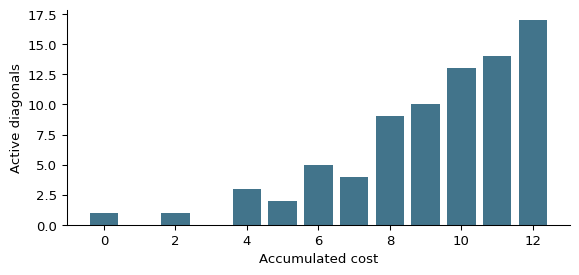

In [2]:
rng = np.random.default_rng(17)
a = rng_dna(rng, 80)
b = a[:24] + "TTT" + a[24:55] + a[58:]
score, width = wavefront(a, b)
reference = gotoh(a, b)[0]
assert score == reference
print(
    f"Optimal affine cost {score} | active match diagonals across levels {sum(width)} | full grid cells {(len(a)+1)*(len(b)+1)}"
)
plt.figure(figsize=(6.2, 3))
plt.bar(range(len(width)), width, color="#42748b")
plt.xlabel("Accumulated cost")
plt.ylabel("Active diagonals")
plt.tight_layout()
plt.show()

## Interpreting the result

Similar strings reach the final diagonal at low cost. Counts of active diagonals illustrate the search and are not measured runtime.

## Exercise

Vary the number of inserted characters. Predict the change in the first cost that reaches the final cell.

## References

[Marco-Sola et al., gap-affine wavefront alignment](https://doi.org/10.1093/bioinformatics/btaa777)

[WFA2-lib, wavefront and bidirectional modes](https://github.com/smarco/WFA2-lib)

[Gotoh, affine gap alignment (1982)](https://doi.org/10.1016/0022-2836(82)90398-9)